In [1]:
# import openai
import os

import json
import argparse
import tqdm
import time
import textstat

import re
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import prettytable
from prettytable import PrettyTable
from scipy.stats import spearmanr, pearsonr, kendalltau
import torch
from transformers import GPT2Tokenizer, GPT2LMHeadModel
import math

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.cluster import KMeans
from collections import defaultdict

from statsmodels.nonparametric.smoothers_lowess import lowess


/users/faculty/sadeghi/.conda/envs/torchenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-07-03 15:27:10.800804: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783103230.814324 1197172 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783103230.818386 1197172 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1783103230.829080 1197172 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target 

In [ ]:
saving_path = '/users/all_data/results/figures'

In [5]:
# Load all the readablity results -- relevance
save_dir = '/users/faculty/sadeghi/exps/all_data/results'
file_path = os.path.join(save_dir, 'output_dicts_readablity_scores_rel.pkl')
with open(file_path, 'rb') as file:
   model_scores_rel, human_scores_rel, read_rel = pickle.load(file)


In [6]:
# Load all the readablity results -- coherence
save_dir = '/users/all_data/results'
file_path = os.path.join(save_dir, 'output_dicts_readablity_scores_coh.pkl')
with open(file_path, 'rb') as file:
    model_scores_coh, human_scores_coh, read_coh = pickle.load(file)


In [9]:
def rescale_list(all_values, new_min=1, new_max=5):
       
    old_min = min(all_values)
    old_max = max(all_values)


    # Rescale function
    def rescale(x):
        return ((x - old_min) / (old_max - old_min)) * (new_max - new_min) + new_min

    # Apply rescaling
    return [rescale(x) for  x in all_values]



In [11]:

def plot_trend_poly(read, human_scores, model_scores):
    
    dict1, dict2, dict3 = read, human_scores, model_scores
    
    # dim_name='Relevance'
    dict_label=['difficult_words', 'Human','Model']
    target_subkey='difficult_words'
    
    values1 = []  # from dict1[target_subkey]
    values2 = []  # from dict2
    values3 = []  # from dict3
    
    for k in dict1:
        # print(k)
        v1_list = dict1[k]
        v2_list = dict2.get(k, [])
        v3_list = dict3.get(k, [])
    
        # print(len(v1_list))
        min_len = min(len(v1_list), len(v2_list), len(v3_list))
        # print(min_len)
        for i in range(min_len):
            subdict = v1_list[i]
            if target_subkey not in subdict:
                continue
            values1.append(subdict[target_subkey])
            values2.append(v2_list[i])
            values3.append(v3_list[i])
    
    # Zip all lists together
    combined = list(zip(values1, values2, values3))
    
    # Sort based on list1 (the first element of each tuple)
    sorted_combined = sorted(combined, key=lambda x: x[0])
    
    # Unzip back into separate lists
    sorted_list1, reordered_list2, reordered_list3 = zip(*sorted_combined)
    
    # Convert back to lists (optional)
    sorted_list1 = list(sorted_list1)
    reordered_list2 = list(reordered_list2)
    reordered_list3 = list(reordered_list3)

        

    x = np.arange(len(reordered_list2))
    
    # Fit 2nd-degree polynomial to both lists
    poly2_list2 = np.poly1d(np.polyfit(x, reordered_list2, deg=2))
    poly2_list3 = np.poly1d(np.polyfit(x, reordered_list3, deg=2))

    # Generate smooth x-values for plotting the curve
    x_smooth = np.linspace(x.min(), x.max(), 1000)
    
    # # Plot original data points
    # plt.scatter(x, reordered_list2, label='List 2 (original)', color='blue')
    # plt.scatter(x, reordered_list3, label='List 3 (original)', color='orange')
    # plt.scatter(indices, sorted_list1, label='List 1', color='green')
    
    # Plot fitted curves
    plt.plot(x_smooth, poly2_list2(x_smooth), label='Human', color='blue', linestyle='--')
    plt.plot(x_smooth, poly2_list3(x_smooth), label='GPT4', color='orange', linestyle='--')
    
    plt.xlabel('Difficult Words')
    # plt.ylabel('Values')
    # plt.title('Trend Approximation Using Polynomial Fit')
    plt.legend()
    plt.grid(True)
    # plt.show()
    plt.tight_layout()
    # plt.savefig(filename, dpi=100)


In [12]:

def plot_trend_lowess(read, human_scores, model_scores, dim, target_subkey='difficult_words'):

    filename = '/users/all_data/results/figures/' + f"lowess_{dim}_{target_subkey}" + '.png'

    dict1, dict2, dict3 = read, human_scores, model_scores
    
    # dim_name='Relevance'
    # dict_label=['difficult_words', 'Human','Model']
   
    
    values1 = []  # from dict1[target_subkey]
    values2 = []  # from dict2
    values3 = []  # from dict3
    
    for k in dict1:
        # print(k)
        v1_list = dict1[k]
        v2_list = dict2.get(k, [])
        v3_list = dict3.get(k, [])
    
        # print(len(v1_list))
        min_len = min(len(v1_list), len(v2_list), len(v3_list))
        # print(min_len)
        for i in range(min_len):
            subdict = v1_list[i]
            if target_subkey not in subdict:
                continue
            values1.append(subdict[target_subkey])
            values2.append(v2_list[i])
            values3.append(v3_list[i])
    
    # Zip all lists together
    combined = list(zip(values1, values2, values3))
    
    # Sort based on list1 (the first element of each tuple)
    sorted_combined = sorted(combined, key=lambda x: x[0])
    
    # Unzip back into separate lists
    sorted_list1, reordered_list2, reordered_list3 = zip(*sorted_combined)
    
    # Convert back to lists (optional)
    sorted_list1 = list(sorted_list1)
    reordered_list2 = list(reordered_list2)
    reordered_list3 = list(reordered_list3)

        

    x = np.arange(len(reordered_list2))

    # LOWESS smoothing
    lowess_result2 = lowess(reordered_list2, x, frac=0.2)  # 'frac' is the smoothing span (0 to 1)
    lowess_result3 = lowess(reordered_list3, x, frac=0.2)  # 'frac' is the smoothing span (0 to 1)
    
    # Plot
    # plt.scatter(x, reordered_list2, label='Original', color='gray')
    
    plt.plot(lowess_result2[:, 0], lowess_result2[:, 1], label='Human', color='blue')
    plt.plot(lowess_result3[:, 0], lowess_result3[:, 1], label='GPT4', color='orange')
    
    
    
    plt.xlabel(target_subkey)
    # plt.ylabel('Values')
    # plt.title('Trend Approximation Using Polynomial Fit')
    plt.legend()
    plt.grid(True)
    # plt.show()
    plt.tight_layout()
    plt.savefig(filename, dpi=100)
    # plt.show()


In [58]:
import numpy as np

def rolling_quantiles(y, window=30):
    q10, q50, q90 = [], [], []

    for i in range(len(y)):
        start = max(0, i - window // 2)
        end = min(len(y), i + window // 2 + 1)

        segment = y[start:end]

        q10.append(np.percentile(segment, 10))
        q50.append(np.percentile(segment, 50))
        q90.append(np.percentile(segment, 90))

    return np.array(q10), np.array(q50), np.array(q90)

In [104]:
def get_trend_lowess(read, human_scores, model_scores,target_subkey):


    dict1, dict2, dict3 = read, human_scores, model_scores
    
    # dim_name='Relevance'
    # dict_label=['difficult_words', 'Human','Model']
   
    
    values1 = []  # from dict1[target_subkey]
    values2 = []  # from dict2
    values3 = []  # from dict3
    
    for k in dict1:
        # print(k)
        v1_list = dict1[k]
        v2_list = dict2.get(k, [])
        v3_list = dict3.get(k, [])
    
        # print(len(v1_list))
        min_len = min(len(v1_list), len(v2_list), len(v3_list))
        # print(min_len)
        for i in range(min_len):
            subdict = v1_list[i]
            if target_subkey not in subdict:
                continue
            values1.append(subdict[target_subkey])
            values2.append(v2_list[i])
            values3.append(v3_list[i])
    
    # Zip all lists together
    combined = list(zip(values1, values2, values3))
    
    # Sort based on list1 (the first element of each tuple)
    sorted_combined = sorted(combined, key=lambda x: x[0])
    
    # Unzip back into separate lists
    sorted_list1, reordered_list2, reordered_list3 = zip(*sorted_combined)
    
    # Convert back to lists (optional)
    sorted_list1 = list(sorted_list1)
    reordered_list2 = list(reordered_list2)
    reordered_list3 = list(reordered_list3)

    x = np.arange(len(reordered_list2))

    diff = np.array(reordered_list2) - np.array(reordered_list3)
    lowess_diff = lowess(diff, x, frac=0.2)

        
    # LOWESS smoothing
    lowess_result2 = lowess(reordered_list2, x, frac=0.2)  # 'frac' is the smoothing span (0 to 1)
    lowess_result3 = lowess(reordered_list3, x, frac=0.2)  # 'frac' is the smoothing span (0 to 1)


    return lowess_result2, lowess_result3, sorted_list1, lowess_diff, reordered_list2, reordered_list3

In [105]:
r1_syl_coh, r2_syl_coh, syl_values_coh, syl_diff_coh, rec_list2_syl_coh, rec_list3_syl_coh = get_trend_lowess(read_coh, human_scores_coh, model_scores_coh,target_subkey='syllable_count')
r1_lex_coh, r2_lex_coh, lex_values_coh, lex_diff_coh, rec_list2_lex_coh, rec_list3_lex_coh = get_trend_lowess(read_coh, human_scores_coh, model_scores_coh,target_subkey='lexicon_count')
r1_dif_coh, r2_dif_coh, dif_values_coh, dif_diff_coh, rec_list2_dif_coh, rec_list3_dif_coh = get_trend_lowess(read_coh, human_scores_coh, model_scores_coh,target_subkey='difficult_words')
r1_gun_coh, r2_gun_coh, gun_values_coh, gun_diff_coh, rec_list2_gun_coh, rec_list3_gun_coh = get_trend_lowess(read_coh, human_scores_coh, model_scores_coh,target_subkey='gunning_fog')
r1_smg_coh, r2_smg_coh, smg_values_coh, smg_diff_coh, rec_list2_smg_coh, rec_list3_smg_coh = get_trend_lowess(read_coh, human_scores_coh, model_scores_coh,target_subkey='smog_index')
r1_aut_coh, r2_aut_coh, aut_values_coh, aut_diff_coh, rec_list2_aut_coh, rec_list3_aut_coh = get_trend_lowess(read_coh, human_scores_coh, model_scores_coh,target_subkey='automated_readability_index')


In [64]:
r1_syl_rel, r2_syl_rel, syl_values_rel, syl_diff_rel = get_trend_lowess(read_rel, human_scores_rel, model_scores_rel,target_subkey='syllable_count')
r1_lex_rel, r2_lex_rel, lex_values_rel, lex_diff_rel = get_trend_lowess(read_rel, human_scores_rel, model_scores_rel,target_subkey='lexicon_count')
r1_dif_rel, r2_dif_rel, dif_values_rel, dif_diff_rel = get_trend_lowess(read_rel, human_scores_rel, model_scores_rel,target_subkey='difficult_words')
r1_gun_rel, r2_gun_rel, gun_values_rel, gun_diff_rel = get_trend_lowess(read_rel, human_scores_rel, model_scores_rel,target_subkey='gunning_fog')
r1_smg_rel, r2_smg_rel, smg_values_rel, smg_diff_rel = get_trend_lowess(read_rel, human_scores_rel, model_scores_rel,target_subkey='smog_index')
r1_aut_rel, r2_aut_rel, aut_values_rel, aut_diff_rel = get_trend_lowess(read_rel, human_scores_rel, model_scores_rel,target_subkey='automated_readability_index')


In [134]:
def plot_onefig_lowess(r1_syl,r2_syl,r1_lex,r2_lex,r1_dif,r2_dif,r1_gun,r2_gun,r1_smg,r2_smg,r1_aut,r2_aut,syl_values,lex_values,
                       dif_values,gun_values,smg_values,aut_values,syl_diff,lex_diff,dif_diff, gun_diff,smg_diff, aut_diff, 
                       rec_list2_syl, rec_list3_syl, rec_list2_lex, rec_list3_lex,
                       rec_list2_dif, rec_list3_dif, rec_list2_gun, rec_list3_gun, 
                       rec_list2_smg, rec_list3_smg, rec_list2_aut, rec_list3_aut, dim):


    filename = '/users/faculty/sadeghi/exps/all_data/results/figures/' + f"lowess_onefig_go{dim}" + '.png'

    plt.figure(figsize=(10, 8))    
    plt.subplot(3, 3, 1)

    # --- Original data (scatter) ---
    x = np.arange(len(rec_list2_syl))
    
    plt.plot(x, rec_list2_syl, color='lightblue', alpha=0.4, label='Human (raw)')
    plt.plot(x, rec_list3_syl, color='lightgreen', alpha=0.4, label='AI (raw)')
    
    plt.plot(r1_syl[:, 0], r1_syl[:, 1], label='Human', color='blue')
    plt.plot(r2_syl[:, 0], r2_syl[:, 1], label='GPT4', color='green')
    plt.plot(syl_diff[:, 0], syl_diff[:, 1], label='Diff', color='red')

    

 



    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [str(syl_values[i]) for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel('syllable_count')
    plt.grid(True)
    
 
    
    plt.subplot(3, 3, 2)
    plt.plot(r1_lex[:, 0], r1_lex[:, 1], label='Human', color='blue')
    plt.plot(r2_lex[:, 0], r2_lex[:, 1], label='GPT4', color='green')
    plt.plot(lex_diff[:, 0], lex_diff[:, 1], label='Diff', color='red')

    
    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [str(lex_values[i]) for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel('lexicon_count')
    plt.grid(True)
    
    plt.subplot(3, 3, 3)
    plt.plot(r1_dif[:, 0], r1_dif[:, 1], label='Human', color='blue')
    plt.plot(r2_dif[:, 0], r2_dif[:, 1], label='GPT4', color='green')
    plt.plot(dif_diff[:, 0], dif_diff[:, 1], label='Diff', color='red')

    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [str(dif_values[i]) for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel('difficult_words')
    plt.grid(True)
    
    
    plt.subplot(3, 3, 4)
    plt.plot(r1_gun[:, 0], r1_gun[:, 1], label='Human', color='blue')
    plt.plot(r2_gun[:, 0], r2_gun[:, 1], label='GPT4', color='green')
    plt.plot(gun_diff[:, 0], gun_diff[:, 1], label='Diff', color='red')

    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [f"{gun_values[i]:.2f}" for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel('gunning_fog')
    plt.grid(True)
    
    plt.subplot(3, 3, 5)
    plt.plot(r1_smg[:, 0], r1_smg[:, 1], label='Human', color='lightblue')
    plt.plot(r2_smg[:, 0], r2_smg[:, 1], label='GPT4', color='lightgreen')
    plt.plot(smg_diff[:, 0], smg_diff[:, 1], label='Diff', color='red')

    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [f"{smg_values[i]:.2f}" for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel('smog_index')
    plt.grid(True)
    
    plt.subplot(3, 3, 6)
    plt.plot(r1_aut[:, 0], r1_aut[:, 1], label='Human', color='blue')
    plt.plot(r2_aut[:, 0], r2_aut[:, 1], label='GPT4', color='green')
    plt.plot(aut_diff[:, 0], aut_diff[:, 1], label='Diff', color='red')

    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [f"{aut_values[i]:.2f}" for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel('automated_readability_index')
    plt.grid(True)

    
    plt.legend()
    # plt.show()
    plt.tight_layout()
        
    # plt.savefig(filename, bbox_inches='tight', dpi=100)


In [211]:
def plot_summary(plt,rec_list2,rec_list3,r1,r2,diff,values,xlabel):

    x = np.arange(len(rec_list2))   
    plt.plot(x, rec_list2, alpha=0.4, label='_nolegend_', color='lightblue')
    plt.plot(x, rec_list3, alpha=0.4, label='_nolegend_', color='lightgreen')
    
    plt.plot(r1[:, 0], r1[:, 1], label='Human', color='blue')
    plt.plot(r2[:, 0], r2[:, 1], label='GPT4', color='green')
    plt.plot(diff[:, 0], diff[:, 1], label='Diff', color='red')
    tick_positions = [0, 500, 1000, 1500]
    tick_labels = [f"{values[i]:.0f}" for i in tick_positions]
    plt.xticks(tick_positions, tick_labels, rotation=45)
    plt.xlabel(xlabel)
    plt.grid(True)


In [212]:
def plot_onefig_lowess(r1_syl,r2_syl,r1_lex,r2_lex,r1_dif,r2_dif,r1_gun,r2_gun,r1_smg,r2_smg,r1_aut,r2_aut,syl_values,lex_values,
                       dif_values,gun_values,smg_values,aut_values,syl_diff,lex_diff,dif_diff, gun_diff,smg_diff, aut_diff, 
                       rec_list2_syl, rec_list3_syl, rec_list2_lex, rec_list3_lex,
                       rec_list2_dif, rec_list3_dif, rec_list2_gun, rec_list3_gun, 
                       rec_list2_smg, rec_list3_smg, rec_list2_aut, rec_list3_aut, dim):

# def plot_onefig_lowess(r1_syl,r2_syl,r1_lex,r2_lex,r1_dif,r2_dif,r1_gun,r2_gun,r1_smg,r2_smg,r1_aut,r2_aut,syl_values,lex_values,
#                        dif_values,gun_values,smg_values,aut_values,syl_diff,lex_diff,dif_diff, gun_diff,smg_diff, aut_diff,  dim):

    filename = '/users/faculty/sadeghi/exps/all_data/results/figures/' + f"lowess_onefig_{dim}_update" + '.png'

    plt.figure(figsize=(10, 8))    
    plt.subplot(3, 3, 1) 
    plot_summary(plt,rec_list2_syl,rec_list3_syl,r1_syl,r2_syl,syl_diff,syl_values,'syllable_count')

    
    plt.subplot(3, 3, 2)
    plot_summary(plt,rec_list2_lex,rec_list3_lex,r1_lex,r2_lex,lex_diff,lex_values,'lexicon_count')

    
    plt.subplot(3, 3, 3)
    plot_summary(plt,rec_list2_dif,rec_list3_dif,r1_dif,r2_dif,dif_diff,dif_values,'difficult_words')


    
    plt.subplot(3, 3, 4)
    plot_summary(plt,rec_list2_gun,rec_list3_gun,r1_gun,r2_gun,gun_diff,gun_values,'gunning_fog')

    
    plt.subplot(3, 3, 5)
    plot_summary(plt,rec_list2_smg,rec_list3_smg,r1_smg,r2_smg,smg_diff,smg_values,'smog_index')

    
    plt.subplot(3, 3, 6)
    plot_summary(plt,rec_list2_aut,rec_list3_aut,r1_aut,r2_aut,aut_diff,aut_values,'automated_readability_index')


    plt.legend()
    # plt.show()
    plt.tight_layout()
        
    plt.savefig(filename, bbox_inches='tight', dpi=100)


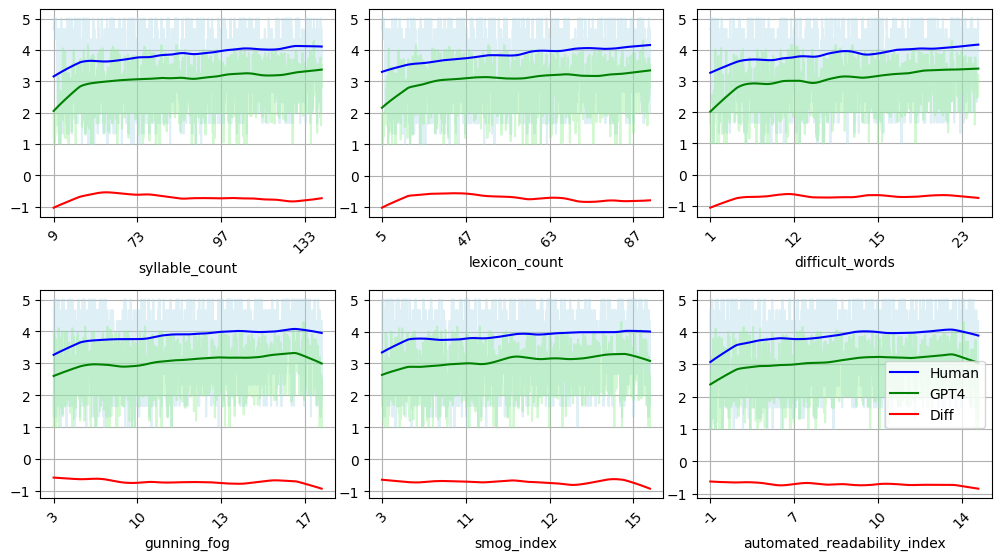

In [213]:
plot_onefig_lowess(r1_syl_rel, r2_syl_rel, r1_lex_rel, r2_lex_rel, r1_dif_rel, r2_dif_rel, r1_gun_rel, r2_gun_rel, r1_smg_rel, r2_smg_rel, r1_aut_rel, r2_aut_rel, syl_values_rel, lex_values_rel,
                       dif_values_rel, gun_values_rel, smg_values_rel, aut_values_rel, syl_diff_rel, lex_diff_rel, dif_diff_rel, gun_diff_rel, smg_diff_rel, aut_diff_rel,rec_list2_syl_coh, rec_list3_syl_coh, rec_list2_lex_coh, rec_list3_lex_coh,
                       rec_list2_dif_coh, rec_list3_dif_coh, rec_list2_gun_coh, rec_list3_gun_coh, 
                       rec_list2_smg_coh, rec_list3_smg_coh, rec_list2_aut_coh, rec_list3_aut_coh,'rel')

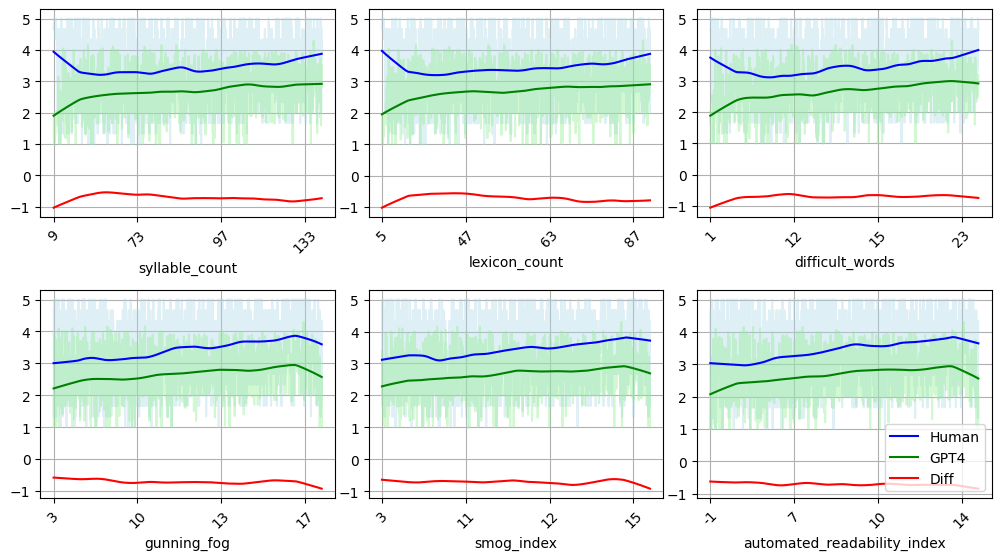

In [214]:
plot_onefig_lowess(r1_syl_coh, r2_syl_coh, r1_lex_coh, r2_lex_coh, r1_dif_coh, r2_dif_coh, r1_gun_coh, r2_gun_coh, r1_smg_coh, r2_smg_coh, r1_aut_coh, r2_aut_coh, syl_values_coh, lex_values_coh,
                       dif_values_coh, gun_values_coh, smg_values_coh, aut_values_coh, syl_diff_rel, lex_diff_rel, dif_diff_rel, gun_diff_rel, smg_diff_rel, aut_diff_rel,rec_list2_syl_coh, rec_list3_syl_coh, rec_list2_lex_coh, rec_list3_lex_coh,
                       rec_list2_dif_coh, rec_list3_dif_coh, rec_list2_gun_coh, rec_list3_gun_coh, 
                       rec_list2_smg_coh, rec_list3_smg_coh, rec_list2_aut_coh, rec_list3_aut_coh,'coh')